**Disciplina:** Tópicos Especiais de Energia – Transferência de Calor utilizando PINNs (UFABC, 3º quadrimestre de 2026)
**Professores:** Prof. Dr. Daniel Jonas Dezan e Prof. MSc. Paulo de Souza Silva
**Aluno:** _preencher com o nome completo_
**Lista 2 – Condução e Solução de Blasius em Python**

Obs.: notebook desenvolvido com auxílio de ferramentas de IA, como permitido no enunciado; o código e os resultados foram executados e conferidos.

# **Exercício 2 – Condução de calor com geração de energia e diferenças finitas**

**Notebook de apoio:** `Aula03_Parte1_1D_Estacionario.ipynb`

## **Enunciado (resumo)**

Parede plana de espessura total $2L = L_c = 0{,}5$ m, domínio $-L \le x \le L$ ($L = 0{,}25$ m). As faces estão em $T_{s1} = T_{s2} = 500$ K. Há geração volumétrica uniforme $\dot q = 1{,}5\times10^6$ W/m³ e $k = 150$ W/(m·K).

A solução analítica é

$$
T(x) = \frac{\dot q L^2}{2k}\left(1-\frac{x^2}{L^2}\right) + \frac{T_{s2}-T_{s1}}{2L}\,x + \frac{T_{s2}+T_{s1}}{2}.
$$

## **Formulação**

A equação governante é

$$
\frac{d^2T}{dx^2} + \frac{\dot q}{k} = 0 .
$$

Como $T_{s1}=T_{s2}$, o termo linear se anula e o perfil é uma **parábola simétrica**, com máximo no centro ($x=0$):

$$
T_{max} = T(0) = \frac{\dot q L^2}{2k} + T_s .
$$

In [1]:
# Bibliotecas utilizadas
import os
import numpy as np                  # funções matemáticas e vetores
import matplotlib.pyplot as plt     # gráficos

os.makedirs("figuras", exist_ok=True)   # pasta onde as figuras são salvas
plt.rcParams["figure.dpi"] = 110

## Geometria e propriedades
Lc = 0.5          # espessura total [m]
L = Lc / 2        # meia espessura [m]
Ts1 = 500.0       # temperatura em x = -L [K]
Ts2 = 500.0       # temperatura em x = +L [K]
q_dot = 1.5e6     # geração volumétrica [W/m^3]
k = 150.0         # condutividade térmica [W/(m K)]

def T_geracao(x):
    # Solução analítica da parede com geração uniforme
    T_p0 = (Ts2 + Ts1) / 2
    T_p1 = ((Ts2 - Ts1) / (2 * L)) * x
    T_p2 = ((q_dot * L**2) / (2 * k)) * (1 - (x / L)**2)
    return T_p2 + T_p1 + T_p0

## **Item a)** Solução analítica com 25 pontos e temperatura máxima

Temperatura máxima: T_max = 812.50 K em x = 0.000 m
Conferência pela fórmula: q L^2/(2k) + Ts = 812.50 K


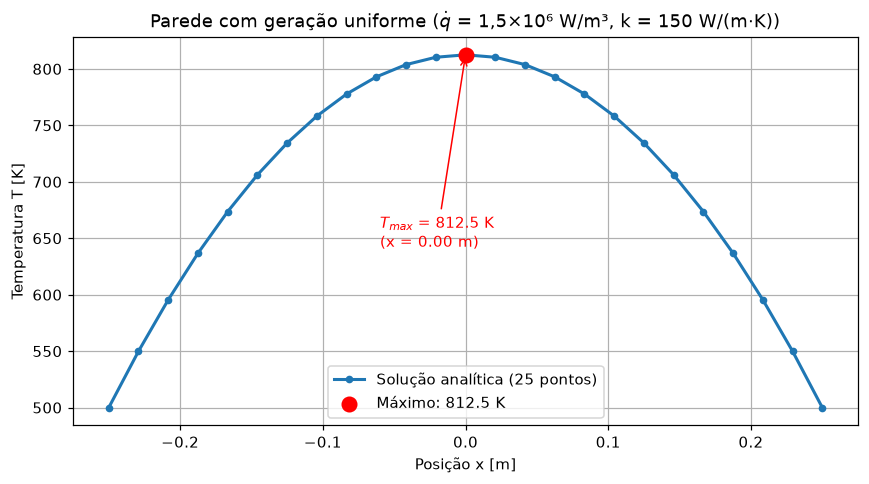

In [2]:
x_25 = np.linspace(-L, L, 25)       # 25 pontos (ímpar -> inclui x = 0)
T_25 = T_geracao(x_25)

i_max = np.argmax(T_25)
x_max, T_max = x_25[i_max], T_25[i_max]
print(f"Temperatura máxima: T_max = {T_max:.2f} K em x = {x_max:.3f} m")
print(f"Conferência pela fórmula: q L^2/(2k) + Ts = {q_dot * L**2 / (2 * k) + Ts1:.2f} K")

plt.figure(figsize=(8, 4.5))
plt.plot(x_25, T_25, "o-", ms=4, linewidth=2, label="Solução analítica (25 pontos)")
plt.scatter(x_max, T_max, s=90, color="red", zorder=3, label=f"Máximo: {T_max:.1f} K")
plt.annotate(f"$T_{{max}}$ = {T_max:.1f} K\n(x = {x_max:.2f} m)",
             xy=(x_max, T_max), xytext=(-0.06, T_max - 170),
             arrowprops=dict(arrowstyle="->", color="red"), color="red")
plt.xlabel("Posição x [m]")
plt.ylabel("Temperatura T [K]")
plt.title(r"Parede com geração uniforme ($\dot q$ = 1,5×10⁶ W/m³, k = 150 W/(m·K))")
plt.grid(True)
plt.legend(loc="lower center")
plt.tight_layout()
plt.savefig("figuras/ex2a_analitica_tmax.png", dpi=300, bbox_inches="tight")
plt.show()

## **Item b)** Montagem manual do sistema $A\,T = b$ com 5 pontos

Com 5 pontos em $[-0{,}25;\,0{,}25]$ m:

$$
\Delta x = \frac{2L}{5-1} = \frac{0{,}5}{4} = 0{,}125 \text{ m},
\qquad x_0=-0{,}25,\; x_1=-0{,}125,\; x_2=0,\; x_3=0{,}125,\; x_4=0{,}25 \text{ m}.
$$

Os pontos $x_0$ e $x_4$ são contornos conhecidos ($T_0 = T_4 = 500$ K). As incógnitas são $T_1, T_2, T_3$.

Termo de geração no lado direito:

$$
-\frac{\dot q}{k}\Delta x^2 = -\frac{1{,}5\times10^6}{150}\,(0{,}125)^2 = -10^4 \times 0{,}015625 = -156{,}25 \text{ K}.
$$

Aplicando $T_{i+1} - 2T_i + T_{i-1} = -\dfrac{\dot q}{k}\Delta x^2$ em cada ponto interno:

- **$i=1$:** $T_2 - 2T_1 + T_0 = -156{,}25 \;\Rightarrow\; -2T_1 + T_2 = -156{,}25 - 500 = -656{,}25$
- **$i=2$:** $T_3 - 2T_2 + T_1 = -156{,}25 \;\Rightarrow\; T_1 - 2T_2 + T_3 = -156{,}25$
- **$i=3$:** $T_4 - 2T_3 + T_2 = -156{,}25 \;\Rightarrow\; T_2 - 2T_3 = -156{,}25 - 500 = -656{,}25$

Os contornos conhecidos ($T_0$ e $T_4$) passam para o lado direito. Na forma matricial:

$$
\underbrace{\begin{bmatrix} -2 & 1 & 0 \\ 1 & -2 & 1 \\ 0 & 1 & -2 \end{bmatrix}}_{A\;(3\times3)}
\begin{bmatrix} T_1 \\ T_2 \\ T_3 \end{bmatrix}
=
\underbrace{\begin{bmatrix} -656{,}25 \\ -156{,}25 \\ -656{,}25 \end{bmatrix}}_{b\;(3\times1)}
$$

In [3]:
# Sistema montado à mão (valores digitados explicitamente)
A = np.array([[-2.0,  1.0,  0.0],
              [ 1.0, -2.0,  1.0],
              [ 0.0,  1.0, -2.0]])

b = np.array([-656.25,
              -156.25,
              -656.25])

T_internos = np.linalg.solve(A, b)

x_5 = np.linspace(-L, L, 5)
print("Matriz A:\n", A)
print("\nVetor b [K]:\n", b)
print("\nTemperaturas internas [K]:")
for nome, xi, Ti in zip(["T1", "T2", "T3"], x_5[1:-1], T_internos):
    print(f"  {nome} (x = {xi:+.3f} m) = {Ti:.4f} K   |   analítica = {T_geracao(xi):.4f} K")

Matriz A:
 [[-2.  1.  0.]
 [ 1. -2.  1.]
 [ 0.  1. -2.]]

Vetor b [K]:
 [-656.25 -156.25 -656.25]

Temperaturas internas [K]:
  T1 (x = -0.125 m) = 734.3750 K   |   analítica = 734.3750 K
  T2 (x = +0.000 m) = 812.5000 K   |   analítica = 812.5000 K
  T3 (x = +0.125 m) = 734.3750 K   |   analítica = 734.3750 K


Os três valores numéricos coincidem com a solução analítica. Isso não é coincidência: a solução exata é um **polinômio de 2º grau**, e o erro de truncamento da diferença central é proporcional a $\dfrac{\Delta x^2}{12}\,\dfrac{d^4T}{dx^4}$, que é **zero** para uma parábola. Por isso, mesmo com só 5 pontos, as diferenças finitas são exatas nos nós.

## **Item c)** Diferenças finitas com 11 pontos (código do notebook de apoio)

In [4]:
# Código do notebook de apoio, com N = 11
N_fd_2 = 11
x_fd_2 = np.linspace(-L, L, N_fd_2)
dx_fd_2 = x_fd_2[1] - x_fd_2[0]

M_fd_2 = np.zeros((N_fd_2, N_fd_2))
b_fd_2 = np.zeros(N_fd_2)

# Condição de contorno em x = -L
M_fd_2[0, 0] = 1
b_fd_2[0] = Ts1

# Equação nos pontos internos
for i in range(1, N_fd_2 - 1):
    M_fd_2[i, i - 1] = 1
    M_fd_2[i, i] = -2
    M_fd_2[i, i + 1] = 1
    b_fd_2[i] = -(q_dot / k) * dx_fd_2**2

# Condição de contorno em x = L
M_fd_2[-1, -1] = 1
b_fd_2[-1] = Ts2

T_fd_2 = np.linalg.solve(M_fd_2, b_fd_2)

print(f"Delta x = {dx_fd_2:.3f} m\n")
print(" i |   x [m]  |  T_DF [K]  | T_analítica [K] |  tipo")
print("---|----------|------------|-----------------|-----------")
for i, (xi, Ti) in enumerate(zip(x_fd_2, T_fd_2)):
    tipo = "contorno" if i in (0, N_fd_2 - 1) else "interno"
    print(f"{i:2d} | {xi:+.3f}   | {Ti:10.4f} | {T_geracao(xi):15.4f} | {tipo}")

Delta x = 0.050 m

 i |   x [m]  |  T_DF [K]  | T_analítica [K] |  tipo
---|----------|------------|-----------------|-----------
 0 | -0.250   |   500.0000 |        500.0000 | contorno
 1 | -0.200   |   612.5000 |        612.5000 | interno
 2 | -0.150   |   700.0000 |        700.0000 | interno
 3 | -0.100   |   762.5000 |        762.5000 | interno
 4 | -0.050   |   800.0000 |        800.0000 | interno
 5 | +0.000   |   812.5000 |        812.5000 | interno
 6 | +0.050   |   800.0000 |        800.0000 | interno
 7 | +0.100   |   762.5000 |        762.5000 | interno
 8 | +0.150   |   700.0000 |        700.0000 | interno
 9 | +0.200   |   612.5000 |        612.5000 | interno
10 | +0.250   |   500.0000 |        500.0000 | contorno


## **Item d)** Comparação entre a solução analítica e diferenças finitas

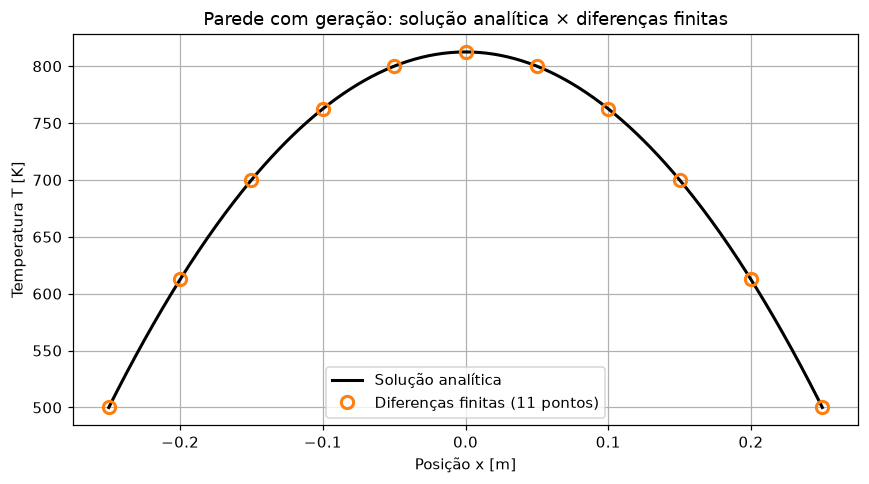

Erro absoluto máximo nos nós: 2.27e-13 K


In [5]:
x_denso = np.linspace(-L, L, 400)
erro_nos = np.abs(T_fd_2 - T_geracao(x_fd_2))

plt.figure(figsize=(8, 4.5))
plt.plot(x_denso, T_geracao(x_denso), "k", linewidth=2, label="Solução analítica")
plt.plot(x_fd_2, T_fd_2, "o", ms=8, mfc="none", mew=2, color="tab:orange",
         label="Diferenças finitas (11 pontos)")
plt.xlabel("Posição x [m]")
plt.ylabel("Temperatura T [K]")
plt.title("Parede com geração: solução analítica × diferenças finitas")
plt.grid(True)
plt.legend(loc="lower center")
plt.tight_layout()
plt.savefig("figuras/ex2d_analitica_vs_df.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Erro absoluto máximo nos nós: {erro_nos.max():.2e} K")

## **Discussão**

- Os 11 pontos de diferenças finitas caem **exatamente** sobre a curva analítica. O erro nos nós é da ordem de $10^{-13}$ K, ou seja, apenas arredondamento de ponto flutuante.
- O motivo é o mesmo do item b): a solução exata é uma parábola. A aproximação central da segunda derivada é exata para polinômios de até 3º grau, porque o erro de truncamento depende de $d^4T/dx^4 = 0$.
- A diferença entre as soluções aparece **entre os nós**. A solução numérica só fornece valores nos pontos da malha, e ligar esses pontos por retas subestima a curvatura da parábola. Aumentar o número de pontos melhora a representação *visual* do perfil, não os valores nodais (que já são exatos).
- Em problemas com geração não uniforme, $k(T)$ variável ou outras condições de contorno, a solução deixa de ser parabólica e o erro nos nós passa a ser $\mathcal{O}(\Delta x^2)$, diminuindo com o refinamento da malha.